In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Generalization in Deep Learning

In that section we saw what usually happens when a
model has as many parameters as training examples. A polynomial with one
weight per training example passed through all 20 of its training points
and missed new points by orders of magnitude. The MLP of
that section would seem to be in the same danger. Its
$784 \times 256 + 256 + 256 \times 10 + 10 = 203{,}530$ parameters come to
about 3.4 for each of the 60,000 Fashion-MNIST training images, enough to
memorize them. Yet it does not: its accuracy on test images, about
87%, is only a few points below its accuracy of about 89% on the training
images. Why does a network that can memorize its training data generalize
anyway? Something other than the number of parameters keeps it from
memorizing.

We need to know what that is, because the width of a network, the length of
its training, and its regularization are all chosen for the sake of
generalization. The answer is not completely known, so this section measures.
We first show that the MLP can fit labels that carry no information, so its
capacity alone cannot explain why it generalizes. Then we follow the test
error of a simpler network as its width grows past the number of training
examples, and see it fall a second time. Both observations point to the
training algorithm: among the many parameter settings that fit the data,
gradient descent finds particular ones, and we work out which in two cases
that can be solved exactly. Finally, the order in which gradient descent fits
the examples turns stopping early into a regularizer. We stay with experiments
and with exact results about simple models; theories that bound the test error
of deep networks directly are still being developed.

## Memorization and Capacity

### Random Labels

The direct test of capacity is to train the network on labels drawn at
random, independently of the images, as @zhang2021understanding did
for image classifiers. There is no pattern to learn from such labels, so a
network that fits them has memorized them. To keep the experiment fast, we
train on 1,000 Fashion-MNIST images, which gives the MLP about 200
parameters per image.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

We draw 2,000 training images at random, 1,000 to train on and 1,000 to hold
out for validation later, and take the first 2,000 test images. All of them
are flattened into NumPy arrays of 784 pixels.

In [2]:
data = d2l.FashionMNIST(batch_size=2000)
X, y = next(iter(data.train_dataloader()))          # 2,000 random images
X_test, y_test = next(iter(data.val_dataloader()))  # the first 2,000
X, y, X_test, y_test = (d2l.numpy(a) for a in (X, y, X_test, y_test))
X, X_test = X.reshape(2000, -1), X_test.reshape(2000, -1)
X_train, y_train, X_val, y_val = X[:1000], y[:1000], X[1000:], y[1000:]

Two small helpers run the experiments. `ArrayData` serves arrays as
minibatches. `Tracker` is a `Trainer` that trains on a GPU if there is one
and, after every epoch, measures the accuracy of the model on each of a set
of named datasets, the training images among them, and appends it to the
list `accuracy[name]`.

In [3]:
class ArrayData(d2l.DataModule):
    """Minibatches of the arrays X and y; training batches are shuffled."""
    def __init__(self, X, y, batch_size=64):
        super().__init__()
        self.save_hyperparameters()

    def get_dataloader(self, train):
        return self.get_tensorloader(
            (d2l.tensor(self.X), d2l.tensor(self.y)), train)

class Tracker(d2l.Trainer):
    """A Trainer that records the accuracy on named datasets every epoch."""
    def __init__(self, max_epochs, datasets):
        super().__init__(max_epochs, num_gpus=1)
        self.datasets = datasets
        self.accuracy = {name: [] for name in datasets}
        self.board.display = False  # We plot the accuracies ourselves

    def validate(self):
        for name, dataset in self.datasets.items():
            self.val_dataloader = dataset.val_dataloader()
            self.accuracy[name].append(super().validate()['acc'])
        return {}

The model has the architecture of the MLP of
that section, a hidden layer of 256 ReLUs, but draws its
weights by the He initialization of that section instead of with
a fixed standard deviation of 0.01, with which the hidden layer learns slowly
at first (that section); its biases start at zero. Its
inputs are already flattened.

In [4]:
class MLP(d2l.Classifier):
    def __init__(self, num_hiddens, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.LazyLinear(num_hiddens), nn.ReLU(),
                                 nn.LazyLinear(10))

    def weight_init(self, module):
        if isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, nonlinearity='relu')
            nn.init.zeros_(module.bias)

`corrupt` replaces each label, with probability `fraction`, by a class drawn
uniformly at random; with `fraction=1` no label depends on its image. Does the
network fit true and random labels alike? We train it on both for 200 epochs
of minibatch SGD, with learning rate 0.1 and minibatches of 64 images, and
record the accuracy on the training images and on the test images.

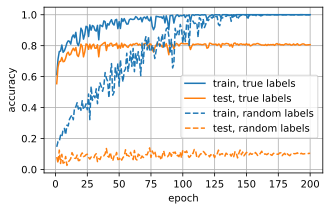

In [5]:
def corrupt(y, fraction, rng):
    """Replace each label, with probability fraction, by a random class."""
    redraw = rng.random(len(y)) < fraction
    return np.where(redraw, rng.integers(0, 10, len(y)), y)

rng = np.random.default_rng()
curves = []
for fraction in (0, 1):
    labels = corrupt(y_train, fraction, rng)
    trainer = Tracker(max_epochs=200, datasets={
        'train': ArrayData(X_train, labels, 1000),
        'test': ArrayData(X_test, y_test, 1000)})
    trainer.fit(MLP(num_hiddens=256, lr=0.1), ArrayData(X_train, labels))
    curves += [trainer.accuracy['train'], trainer.accuracy['test']]
d2l.plot(list(range(1, 201)), curves, 'epoch', 'accuracy',
         fmts=('C0-', 'C1-', 'C0--', 'C1--'), figsize=(5, 3))
d2l.plt.legend(['train, true labels', 'test, true labels',
                'train, random labels', 'test, random labels'],
               loc='center right', bbox_to_anchor=(1, 0.4));

With true labels, training accuracy passes 99% after 60 to 90 epochs, and
test accuracy settles at about 80% to 83%. With random labels, the network needs
longer, 110 to 150 epochs to pass 99%, but it fits them too: training
accuracy reaches 100%, while test accuracy stays near the 10% of guessing. The network, the optimizer, and the images are the same in both
runs; only the labels differ.

In that section we called a class of models that can
fit any labels of its training inputs too flexible for a perfect fit to mean
anything. MLPs of this size come close to such a class for these 1,000
images: they fit a labeling that has nothing to do with the images. Whatever
lets the network generalize from the true labels, it is not a lack of
capacity to memorize.

### Capacity Bounds

Learning theory turns capacity into guarantees. In
that section we met the VC bound: with
probability at least $1 - \delta$ over the draw of $n$ training examples,
every classifier $f$ in a class of VC dimension $v$ satisfies

$$
\epsilon(f) \leq \epsilon_{\mathcal{S}}(f) + c\sqrt{\frac{v + \log(1/\delta)}{n}},
$$

where $\epsilon(f)$ is the population error, $\epsilon_{\mathcal{S}}(f)$ the
training error, and $c$ a constant. The bound guarantees that the training
error carries over to new data once $n$ is large compared with $v$. For a
linear classifier, $v$ is one more than the number of features, the number
of its parameters. If we estimate $v$ the same way for the MLP trained on all
60,000 images, the square root alone is
$\sqrt{203{,}530/60{,}000} \approx 1.8$. An error never exceeds 1, so
unless the constant $c$ is below about 0.55, the bound guarantees nothing.
Neither a smaller constant nor a sharper estimate of $v$ can rescue it: as
exercise 1 shows, random labels
rule out every bound that depends only on the class, $n$, and $\delta$.

### Inductive Bias

If the class does not decide, the choice among the functions that fit the
training data does. A learner that fits $n$ labeled examples must still
decide how to label every other input, and the training data cannot settle
this. Averaged over all ways in which the unseen inputs could be labeled,
every learner has the same expected error, a result known as the *no free
lunch theorem* [@Wolpert.1996]. A learner generalizes on a particular
problem when its preferences among the functions that fit match the way
the problem labels new inputs. These preferences are its *inductive bias*.
The learners we have met make different bets:

| Learner | Inductive bias |
|---|---|
| Linear classifier | classes are separated by hyperplanes |
| Polynomial fit with weight decay | small weights, hence slowly varying curves |
| 1-nearest neighbor | an input has the label of the closest training input |
| MLP trained by gradient descent | the subject of the rest of this section |

The nearest-neighbor rule shows that fitting every training example need not
mean overfitting. It labels each training input correctly by construction,
yet under mild conditions, as the training set grows, its error tends to at
most twice the smallest error any classifier can achieve
[@Cover.Hart.1967]. Fitting
the data exactly is compatible with generalizing; the error is decided by
the labels the learner assigns between the training points.

## Double Descent

### The Interpolation Threshold

In that section, the test error of polynomial fits
fell as the degree rose to 3 and then grew by orders of magnitude up to
degree 19, where the 20 weights fit the 20 training points exactly. The
study stopped there, because beyond that degree the least-squares problem
has infinitely many exact solutions. We now continue past this point, with
a model whose solutions we can compute.

Freeze the hidden layer of the MLP at its random initialization and train
only the output layer. We drop the biases and, instead of cross-entropy,
use the squared loss on one-hot labels, which turns training into linear
least squares. Let $\mathbf{H} = \textrm{ReLU}(\mathbf{X}\mathbf{W}^{(1)})
\in \mathbb{R}^{n \times h}$ be the hidden representation of the $n$
training images with $h$ hidden units, and $\mathbf{Y} \in \mathbb{R}^{n
\times 10}$ their one-hot labels. Fitting chooses the output weights
$\mathbf{W}^{(2)} \in \mathbb{R}^{h \times 10}$ to minimize the squared
error summed over all entries, $\|\mathbf{H}\mathbf{W}^{(2)} -
\mathbf{Y}\|_F^2$.

Each output is a separate least-squares problem with $n$ equations and $h$
unknowns. The MLP of that section fitted 1,000 random
labels with 256 hidden units because all of its 203,530 parameters were
trained. With the hidden layer frozen, each output keeps only its $h$
weights, so an exact fit of $n$ labels needs $h \geq n$. For $h < n$ the
least-squares problem has a unique solution, which usually misses some
labels. At $h = n$ the matrix $\mathbf{H}$ is square. Once we remove the
hidden units that are active on almost no images, as described below, it is
invertible like almost every random square matrix, so exactly one solution
reproduces every label. For $h > n$ there are infinitely many solutions that
reproduce every label, and we take the one of smallest norm.
`np.linalg.lstsq` returns this solution in all three cases. The width
$h = n$, at which an exact fit first becomes possible, is the
*interpolation threshold*.

A network whose hidden layer stays at its random initialization is called a
*random-features* model [@Rahimi.Recht.2007]. Very wide networks
trained with small steps stay close to a linear model of this kind, built
from the gradients at their initialization; this is the *lazy* or *neural
tangent* regime [@Jacot.Gabriel.Hongler.2018]. Networks used in
practice also change their features during training. that section
shows how width-dependent learning rates keep this feature learning from
vanishing as networks grow wider.

We compute the hidden representation once for 10,000 hidden units; the model
with $h$ units uses its first $h$ columns. Since all pixels are nonnegative, a
unit whose weights are negative on most of the bright pixels is active on only
a few images, or on none. Such a unit contributes a column with almost all
entries zero, and two units that are active only on the same image contribute
proportional columns, so that $\mathbf{H}$ loses rank. About one or two units
in a hundred are active on fewer than ten of the 1,000 training images, so we
draw 11,000 units and keep the first 10,000 of those that are active on at
least ten.

In [6]:
W1 = rng.normal(0, np.sqrt(2 / 784), (784, 11000))  # He-initialized, frozen
H, H_test = np.maximum(X_train @ W1, 0), np.maximum(X_test @ W1, 0)
images = (H > 0).sum(axis=0)  # Images on which each unit is active
print(f'units active on fewer than 10 images: {(images < 10).mean():.1%}')
active = np.flatnonzero(images >= 10)[:10000]
H, H_test = H[:, active], H_test[:, active]
Y = np.eye(10)[y_train]                             # One-hot labels

def error(H, W2, y):
    """Fraction of examples whose largest output is not their label."""
    return (np.argmax(H @ W2, axis=1) != y).mean()

units active on fewer than 10 images: 1.8%


How does the error depend on the width $h$? We fit the output layer for
widths from 50 to 10,000 and record the smallest singular value of each
feature matrix, which `lstsq` returns, and the norm of the solution.

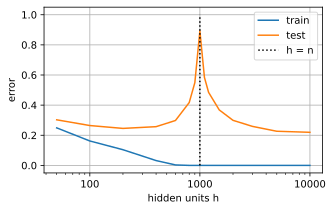

In [7]:
widths = [50, 100, 200, 400, 600, 800, 900, 1000, 1100, 1200, 1500, 2000,
          3000, 5000, 10000]
train_err, test_err, s_min, norm = [], [], {}, {}
for h in widths:
    W2, _, _, s = np.linalg.lstsq(H[:, :h], Y, rcond=None)
    train_err.append(error(H[:, :h], W2, y_train))
    test_err.append(error(H_test[:, :h], W2, y_test))
    s_min[h], norm[h] = s.min(), np.linalg.norm(W2)
d2l.plot([widths, widths, [1000, 1000]], [train_err, test_err, [0, 1]],
         'hidden units h', 'error', legend=['train', 'test', 'h = n'],
         xscale='log', fmts=('C0-', 'C1-', 'k:'), figsize=(5, 3))

The left part of the curve is the U of that section.
Test error falls from about 30% at 50 hidden units to between 21% and 25%
at a few hundred units, and then rises. At the interpolation threshold
$h = n = 1{,}000$, it peaks at about 90%, the error of random guessing.
Beyond the threshold every model fits all of its training labels, yet test
error falls again, and at 10,000 hidden units it reaches 18% to 23%, below
the best width before the threshold. This shape is called *double descent*
[@Belkin.Hsu.Ma.ea.2019]. The plotted training error counts
misclassified images, so it reaches zero already at 800 to 900 hidden units,
where the largest output of each training image belongs to its label
although the squared error is not yet zero; the squared error vanishes only from
$h = n$ on. Past the threshold, the training error cannot tell the models
apart; the test error can.

### Conditioning at the Threshold

Why does the error peak where the number of hidden units equals the number of
examples? At $h = n$ the feature matrix $\mathbf{H}$ is square, and fitting
must solve $\mathbf{H}\mathbf{W}^{(2)} = \mathbf{Y}$ exactly. A random square
matrix is almost always invertible, but in some direction it is nearly
singular: its smallest singular value $s_\textrm{min}$ is close to zero,
and its inverse stretches that direction by $1/s_\textrm{min}$. To
reproduce the labels, the solution needs a large component along it, and
predictions on new images inherit that component. With fewer hidden units,
least squares need not fit every label; with more, many solutions fit, and
the one of smallest norm avoids the nearly singular direction.

In [8]:
for h in (200, 900, 1000, 1100, 10000):
    print(f'h = {h:5d}: smallest singular value {s_min[h]:.1e}, '
          f'norm of W2 {norm[h]:6.1f}')

h =   200: smallest singular value 3.0e-01, norm of W2    6.9
h =   900: smallest singular value 4.1e-02, norm of W2   43.9
h =  1000: smallest singular value 3.3e-04, norm of W2 1712.9
h =  1100: smallest singular value 5.9e-02, norm of W2   36.6
h = 10000: smallest singular value 1.8e+00, norm of W2    3.0


At the threshold the smallest singular value is tens to thousands of times
smaller than at 1,100 hidden units, depending on the draw of the features.
The norm of the solution jumps from about 50 at 900 units to several hundred
or more, often thousands, against about 40 at 1,100 units and 3 at 10,000.
Beyond the threshold, the norm can only shrink as units are added: an exact fit with
$h$ hidden units remains an exact fit with $h + 1$ (give the new unit zero
weight), so the smallest norm among the exact fits cannot grow. The
mathematics appendix analyzes this mechanism in a smaller example
(that section).

The threshold moves with the number of examples, which has a surprising
consequence. With 1,000 hidden units, how does the test error change if we
train on half as many images?

In [9]:
for n in (500, 1000):
    W2 = np.linalg.lstsq(H[:n, :1000], Y[:n], rcond=None)[0]
    test_error = error(H_test[:, :1000], W2, y_test)
    print(f'{n} training images: test error {test_error:.2f}')

500 training images: test error 0.31


1000 training images: test error 0.89


Doubling the training set from 500 to 1,000 images raises the test error
from about a third to about 90%, because the larger set puts the model onto
its interpolation threshold. @nakkiran2021deep observed the same
peaks in deep networks, as the width, the number of training epochs, or the
number of examples varies. The peak sits where training can just barely fit
the training set.

## Implicit Bias of Gradient Descent

The second descent depended on taking the smallest solution among the many
that fit. Nothing in the loss asks for this: every exact fit has zero training
loss. Which fit does gradient descent find? For two models the answer is
known, and in both the choice is made by the training algorithm. Such a
preference of a training algorithm is called its *implicit bias*.

### Minimum-Norm Interpolation

We begin with the random-features model of the double-descent experiment.
Its loss is quadratic, so the fit that gradient descent reaches can be
written down. Consider one output of this model: weights
$\mathbf{w} \in \mathbb{R}^h$, the loss
$L(\mathbf{w}) = \frac{1}{2}\|\mathbf{H}\mathbf{w} - \mathbf{y}\|^2$ with
$h > n$, and a matrix $\mathbf{H}$ whose $n$ rows are linearly independent.
The exact fit of smallest norm is

$$
\mathbf{w}^\star = \mathbf{H}^\top(\mathbf{H}\mathbf{H}^\top)^{-1}\mathbf{y}.
$$

It is a combination of the rows of $\mathbf{H}$, and it reproduces the labels,
since $\mathbf{H}\mathbf{w}^\star = \mathbf{y}$.

**Proposition.** Gradient descent on $L$ started at $\mathbf{w}_0 = \mathbf{0}$,
with a learning rate small enough for it to converge, converges to
$\mathbf{w}^\star$.

**Proof.** The gradient $\mathbf{H}^\top(\mathbf{H}\mathbf{w} - \mathbf{y})$
is a combination of the rows of $\mathbf{H}$. Starting from zero, every
iterate is therefore a combination of the rows, $\mathbf{w}_t =
\mathbf{H}^\top\mathbf{a}_t$ for some $\mathbf{a}_t \in \mathbb{R}^n$, and so
is the limit. At the limit the gradient vanishes, so for this convex loss
the limit is a minimizer. Since the rows of $\mathbf{H}$ are independent,
exact fits exist, so the limit fits exactly:
$\mathbf{H}\mathbf{H}^\top\mathbf{a} = \mathbf{y}$, which gives $\mathbf{a} =
(\mathbf{H}\mathbf{H}^\top)^{-1}\mathbf{y}$ and the limit $\mathbf{w}^\star$.
It remains to see that no exact fit is shorter. Every exact fit is
$\mathbf{w}^\star + \mathbf{v}$ with $\mathbf{H}\mathbf{v} = \mathbf{0}$. Such
a $\mathbf{v}$ is orthogonal to every row of $\mathbf{H}$, hence to
$\mathbf{w}^\star$, so $\|\mathbf{w}^\star + \mathbf{v}\|^2 =
\|\mathbf{w}^\star\|^2 + \|\mathbf{v}\|^2$. $\blacksquare$

the figure shows the argument for one equation in two
unknowns. Every step moves perpendicular to the line of exact fits, so a
start at zero ends at the point of the line closest to the origin. The
component of a start $\mathbf{w}_0$ along the line never changes, so a start
with such a component ends at a different, longer fit.

![Gradient descent on least squares with one equation $\mathbf{h}^\top\mathbf{w} = y$ in two unknowns. The exact fits form a line (green). Each gradient is a multiple of $\mathbf{h}$, so each step moves perpendicular to that line. Started at $\mathbf{0}$ (blue), gradient descent stops at the point of the line closest to the origin, where the dashed circle touches it. Started at $\mathbf{w}_0$ (orange), it stops at a longer exact fit.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-mlp-min-norm.svg)

We check the proposition on a random problem with 20 equations and 100
unknowns, starting once at zero and once at a random point.

In [10]:
H_small = rng.normal(size=(20, 100))
y_small = rng.normal(size=20)
w_star = np.linalg.lstsq(H_small, y_small, rcond=None)[0]
lr = 1 / np.linalg.norm(H_small, 2) ** 2  # Below 2 / largest curvature
for name, w in (('zero', np.zeros(100)), ('random', rng.normal(size=100))):
    for _ in range(2000):
        w = w - lr * H_small.T @ (H_small @ w - y_small)
    residual = np.linalg.norm(H_small @ w - y_small)
    print(f'start {name:6s}: residual {residual:.0e}, norm '
          f'{np.linalg.norm(w):5.2f}, distance to w* '
          f'{np.linalg.norm(w - w_star):.1f}')

start zero  : residual 6e-17, norm  0.48, distance to w* 0.0


start random: residual 1e-15, norm 10.74, distance to w* 10.7


Both runs fit every label. The run from zero ends at the minimum-norm
solution of `lstsq` up to rounding; the run from a random start ends at
another exact fit, more than ten times longer. The minimum-norm solutions
of the double-descent experiment are therefore the ones gradient descent from
zero would find.

### Maximum-Margin Classification

For classification with cross-entropy the situation differs. Take two classes
with labels $y \in \{-1, +1\}$ and a linear score $\mathbf{w}^\top\mathbf{x}$,
so that an example has the margin $m = y \mathbf{w}^\top\mathbf{x}$ and the
loss $\log(1 + \exp(-m))$ of that section. If some $\mathbf{w}$
classifies every training example correctly, no finite $\mathbf{w}$ minimizes
the loss: scaling up a separating $\mathbf{w}$ raises every margin and lowers
every loss. Gradient descent lets $\|\mathbf{w}\|$ grow without bound, and the
question becomes which direction $\mathbf{w}/\|\mathbf{w}\|$ it approaches.
@Soudry.Hoffer.Nacson.ea.2018 proved that it approaches the
*maximum-margin* direction: of all separators, the one whose smallest distance
to a training point is largest. The intuition is that once $\|\mathbf{w}\|$ is
large, the loss of an example is about $\exp(-m)$, so the examples with the
smallest margins dominate the gradient, and gradient descent works mostly on
raising them. the figure shows that the approach is
slow: the training error is zero from the first step, yet the separator is
still turning after $10^5$ steps.

![Gradient descent on the logistic loss for two separable classes, with separators through the origin. Left: the separators after $t = 1$, $10^2$, and $10^4$ steps (gray to blue) turn toward the maximum-margin separator (black), whose margin is dashed; the two examples closest to it are ringed. Right: the angle between $\mathbf{w}_t$ and the maximum-margin direction keeps shrinking long after every training example is classified correctly.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-mlp-max-margin.svg)

Both results concern linear models. For deep networks, statements this exact
are rare: the parameter norm that gradient descent keeps small is not even a
property of the function the network computes, because different parameters
can compute the same function (exercise
6). The next experiment shows a
preference of gradient descent in our MLP that needs no such statement.

## Early Stopping

### Label Noise

Gradient descent also has a preference in time.
@Arpit.Jastrzebski.Ballas.ea.2017 observed that networks trained on
partly mislabeled data fit the correctly labeled examples first and the
mislabeled ones later. We repeat their experiment on our 1,000 images,
redrawing 20% of the labels at random. A redrawn label is correct one time
in ten, so about 18% of the labels end up wrong. After every epoch we measure
the accuracy on the correctly labeled training images, on the mislabeled
training images against their wrong labels, and on the 1,000 held-out
training images, our validation set.

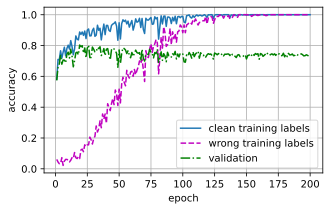

In [11]:
labels = corrupt(y_train, 0.2, rng)
wrong = labels != y_train
trainer = Tracker(max_epochs=200, datasets={
    'clean': ArrayData(X_train[~wrong], labels[~wrong], 1000),
    'mislabeled': ArrayData(X_train[wrong], labels[wrong], 1000),
    'validation': ArrayData(X_val, y_val, 1000),
    'test': ArrayData(X_test, y_test, 1000)})
trainer.fit(MLP(num_hiddens=256, lr=0.1), ArrayData(X_train, labels))
acc = trainer.accuracy
d2l.plot(list(range(1, 201)), [acc['clean'], acc['mislabeled'],
                               acc['validation']], 'epoch', 'accuracy',
         legend=['clean training labels', 'wrong training labels',
                 'validation'], figsize=(5, 3))

The two kinds of training images are fit at very different speeds. After 20
epochs the network reproduces the labels of more than 80% of the correctly
labeled images, but those of fewer than one in five of the mislabeled ones.
Validation accuracy peaks in this first phase, within the first 50 epochs. Then
the network memorizes the wrong labels, nearly all of them after about 100 to 160
epochs, and validation accuracy declines by several points. Memorizing the
mislabeled examples costs accuracy on new images.

### The Stopping Rule

*Early stopping* exploits this order. It monitors the validation accuracy
after every epoch and keeps the parameters of the best epoch. In practice,
training ends once the validation accuracy has not improved for a number of
epochs called the *patience* (exercise
2). Here we pick the best epoch from
the recorded history and judge the choice on the test images, which played no
part in it.

In [12]:
best = int(np.argmax(acc['validation']))
print(f'best validation accuracy after epoch {best + 1}: '
      f'test accuracy {acc["test"][best]:.3f}')
print(f'after all 200 epochs: test accuracy {acc["test"][-1]:.3f}')

best validation accuracy after epoch 19: test accuracy 0.788
after all 200 epochs: test accuracy 0.752


Stopping at the best validation epoch gains about one to five points of
test accuracy over training to the end. Early stopping limits how far the
parameters move from their initialization, much as weight decay limits
their size; for least squares the two are nearly equivalent (exercise
5). It also saves the
compute of the remaining epochs.

The rule assumes that validation accuracy does not rise again after a long
plateau. @Power.Burda.Edwards.ea.2022 found a counterexample on
small algorithmic tasks such as addition modulo a prime. Networks trained
with weight decay fit their training set within about a thousand steps, stay
near chance on validation data for many times as long, and generalize only
after a hundred to a thousand times as many steps (the figure). This is called *grokking*. A patience
rule would have stopped long before.

![Grokking, schematically, after @Power.Burda.Edwards.ea.2022 . On a small algorithmic task, training accuracy (gray) saturates within about a thousand steps. Validation accuracy (blue) stays near chance for more than ten times as many steps and reaches the training accuracy two to three orders of magnitude after it.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-mlp-grokking.svg)

Gradient descent, not the parameter count, decides which of the many exact
fits a network finds. From zero it finds the minimum-norm fit, on separable
data it approaches the maximum-margin separator, and on noisy labels it fits
the clean examples first. Left to run, it also memorizes the noise. The next
section studies dropout, a perturbation applied during training that may
change what the network prefers to fit.

## Summary

An MLP with more parameters than training examples generalizes, although it
can also fit random labels. Counting parameters, or any
capacity measure of the class alone, therefore cannot explain its
generalization, and the VC bound is vacuous for it. A random-features model
shows what happens past the interpolation threshold: test error peaks where
the number of hidden units equals the number of examples, because the feature
matrix is nearly singular there, and falls again as the width grows. Which of
the many exact fits a model finds is decided by the training algorithm:
gradient descent from zero finds the minimum-norm fit for least squares and
approaches the maximum-margin separator for the logistic loss. With noisy
labels it fits the correctly labeled examples first, so stopping at the best
validation epoch keeps the clean fit and discards the memorized noise.

## Exercises

1. **Limits of complexity measures.** Consider a generalization bound that
   holds for every data distribution: with probability at least
   $1 - \delta$ over the draw of $n$ training examples, every classifier
   $f$ in a class $\mathcal{F}$ satisfies

    $$\epsilon(f) \leq \epsilon_{\mathcal{S}}(f) + B(\mathcal{F}, n, \delta).$$

    Here $\epsilon(f)$ is the population error, $\epsilon_{\mathcal{S}}(f)$ is
    the training error, and the term $B$ depends only on $\mathcal{F}$, $n$,
    and $\delta$, as the term $c\sqrt{(v + \log(1/\delta))/n}$ of the VC
    bound in that section does. Suppose that training
    finds a member of an MLP class $\mathcal{F}$ with zero training error on
    the 60,000 Fashion-MNIST training images, both with the true labels and
    with labels drawn uniformly at random from the 10 classes, independently
    of the images, as @zhang2021understanding observed for image
    classifiers.
    1. What population error does every classifier have on the random-label
       data? What lower bound on $B(\mathcal{F}, n, \delta)$ follows?
    1. What does the bound then guarantee about the population error of the
       network trained on the true labels?
1. [code] **Patience-based stopping.** `FashionMNIST` uses the Fashion-MNIST
   test set as its validation data, so hold out 10,000 training images as a
   validation set instead. Train an MLP with one hidden layer of 256 units,
   as in that section, on the remaining images for a
   fixed number of epochs large enough to overfit, and record the validation loss
   and the test accuracy after every epoch. A patience rule with tolerance
   $\tau$ and patience $k$ stops once the validation loss has failed to
   improve on its best value by more than $\tau$ for $k$ consecutive
   epochs. It then retains the parameters of the epoch with the lowest
   validation loss so far.
    1. Fix $\tau$ and apply the rule to the recorded curves for
       $k \in \{1, 5, 20\}$. For each $k$, report the stopping epoch, the
       retained epoch, and the test accuracy at both.
    1. How does the test accuracy at the retained epoch depend on $k$?
       Relate the dependence to the epoch-to-epoch fluctuation of the
       validation loss.

    *Adapted from Michael Nielsen,
    [Neural Networks and Deep Learning](http://neuralnetworksanddeeplearning.com/chap3.html),
    Chapter 3.*
1. [code] **More data can hurt.** Fix the random-features model at 1,000
   hidden units and fit it, as in that section, on the
   first $n$ of 2,000 training images for $n$ from 100 to 2,000.
    1. Plot the test error against $n$. Where does it peak, and how does the
       peak compare with the error at $n = 2{,}000$?
    1. Plot the smallest singular value of the feature matrix against $n$ and
       explain the shape of the error curve with it.
    1. Repeat with 500 and 2,000 hidden units. Where does the peak move?
1. [code] **Weight decay at the threshold.** Replace the minimum-norm fit of
   the double-descent experiment by the ridge solution
   $\mathbf{W}^{(2)} = (\frac{1}{n}\mathbf{H}^\top\mathbf{H} + \lambda
   \mathbf{I})^{-1}\frac{1}{n}\mathbf{H}^\top\mathbf{Y}$ of
   that section, which, as there, averages the squared error
   over the $n$ examples.
    1. Plot the test error against the width for $\lambda \in \{10^{-5},
       10^{-3}, 10^{-1}\}$. What happens to the peak at $h = n$?
    1. Show that the ridge solution approaches the minimum-norm solution as
       $\lambda \to 0$ for $h > n$. Hint: write
       $(\frac{1}{n}\mathbf{H}^\top\mathbf{H} + \lambda
       \mathbf{I})^{-1}\frac{1}{n}\mathbf{H}^\top =
       \mathbf{H}^\top(\mathbf{H}\mathbf{H}^\top + n\lambda \mathbf{I})^{-1}$.
    1. For each width, choose $\lambda$ on the 1,000 validation images. Does
       the curve of the tuned model still descend twice?
1. **Early stopping and weight decay.** ● Early stopping limits the number
   of training epochs where weight decay limits the weights. Linear least
   squares makes this precise. Let $\mathbf{X}^\top\mathbf{X}/n$ have
   eigenvalues $\mu_i > 0$, let $\mathbf{w}^*$ minimize
   $L(\mathbf{w}) = \frac{1}{2n}\|\mathbf{X}\mathbf{w} - \mathbf{y}\|^2$, and
   run gradient descent on $L$ from $\mathbf{w}_0 = \mathbf{0}$ with learning
   rate $\eta < 1/\max_i \mu_i$.
    1. Show that after $t$ steps the coordinate of $\mathbf{w}_t$ along the
       $i$-th eigenvector equals $1 - (1 - \eta\mu_i)^t$ times that of
       $\mathbf{w}^*$.
    1. The minimizer of $L(\mathbf{w}) + \frac{\lambda}{2}\|\mathbf{w}\|^2$
       scales the same coordinate by
       $\mu_i/(\mu_i + \lambda)$ (that section). For which
       $\lambda$, as a function of $\eta$ and $t$, do the two factors
       approximately agree both in the directions with $\eta\mu_i t \ll 1$
       and in those with $\eta\mu_i t \gg 1$?

    *Adapted from Ian Goodfellow, Yoshua Bengio, and Aaron Courville,
    [Deep Learning](https://www.deeplearningbook.org/contents/regularization.html),
    Section 7.8.*
1. **Implicit bias of the logistic loss.** ● For linearly separable data,
   gradient descent on the logistic loss converges in direction to the
   maximum-margin separator [@Soudry.Hoffer.Nacson.ea.2018]. Take
   labels $y_i \in \{-1, +1\}$.
    1. For a linear predictor $f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x}$,
       show that on separable data the loss
       $\sum_i \log\left(1 + \exp(-y_i \mathbf{w}^\top\mathbf{x}_i)\right)$
       is positive for every $\mathbf{w}$ but has infimum zero. Conclude that
       $\|\mathbf{w}_t\|$ grows without bound when gradient descent drives
       the loss to zero, so that only the direction
       $\mathbf{w}_t/\|\mathbf{w}_t\|$ can converge.
    1. For a two-layer ReLU network
       $f(\mathbf{x}) = \sum_j v_j \max(0, \mathbf{w}_j^\top\mathbf{x})$,
       show that replacing $(\mathbf{w}_j, v_j)$ by
       $(c_j\mathbf{w}_j, v_j/c_j)$ with $c_j > 0$ leaves $f$ unchanged. Find
       the smallest value of $\sum_j (\|\mathbf{w}_j\|^2 + v_j^2)$ over these
       rescalings. Explain why a margin measured with the parameter norm of
       the network, unlike one measured with $\|\mathbf{w}\|$ for the linear
       predictor, is not a property of the function $f$ alone.
1. [extended] **Epoch-wise double descent.** ● Take an MLP with one hidden
   layer of 256 units, as in that section, on
   Fashion-MNIST and randomly relabel
   15% of the training examples. Train far past convergence (several hundred
   epochs). After every epoch, record the test error and the training
   accuracy on the relabeled examples, measured against their new labels.
   Plot both against the epoch count on a log axis.
    1. Does the test error descend a second time after the initial rise?
    1. At which epoch does the test error peak, and what fraction of the
       relabeled examples has the network fitted by then?
    1. Repeat with 5% and 30% of the examples relabeled. How do the height
       and the epoch of the peak change?
    1. Suppose a patience rule with $k = 20$ and $\tau = 0$ monitored the
       test-error curve of the 15% run as if it were a validation curve. At
       which epoch would the rule stop, and how does the test error there
       compare with the test error at the end of training?
1. [extended] **Grokking.** ●● Reproduce the setup of
   @Power.Burda.Edwards.ea.2022: train a small network (they use a
   two-layer transformer, but a wide MLP on one-hot pairs also works) to
   predict $c = (a + b) \bmod 97$ from the pair $(a, b)$, using a random 50%
   of all pairs for training, with weight decay, for $10^5$ or more steps.
   Plot training and validation accuracy against the logarithm of the step
   count, and compare with the figure. How does the delay before
   generalization change with the training fraction and with the
   weight-decay strength?

[Discussions](https://d2l.discourse.group/t/7473)